# Segmenting mitochondria in EM images by asking questions

ARGUS with the CDeep3M skill (`kaiucsd/argus-ncuvo:0.2-cu118` or `0.2-cpu`). The questions use the
sample SBEM mitochondria dataset that ships with CDeep3M: 20 labelled training slices and 10 labelled
validation slices of 1024 x 1024 pixels.

In [ ]:
%reset

## 1. What is available here?

In [2]:
%%ask
What can I do with CDeep3M here? Which models are available, what hardware does this pod have, and
roughly how long would fine-tuning a model take?

All four reports came back cleanly on the first run — no retries needed.

## What you can do here

CDeep3M is set up and working on this pod: you can segment mitochondria in electron-microscopy images with the pretrained model, fine-tune it on your own labelled slices, score a segmentation against expert labels, compare models side by side, and view the results. The four reports below cover the hardware, the models, the tunable settings and the sample data that is already on disk.

## Environment

| | |
|---|---|
| GPU | NVIDIA GeForce RTX 2080 Ti, 11264 MiB |
| PyTorch | 2.7.1+cu118, GPU training available |
| CPUs available | 2 |
| Project folder (kept): own models, predictions, settings | `/home/jovyan/work/_User-Persistent-Storage_CephBlock_/Sage_demo/cdeep3m`, 2.1 GB free |
| Temporary folder: pretrained models, training data, training runs | `/tmp/cdeep3m`, 235.2 GB free, not kept when the pod stops |

Training with the current settings: about 0.4 s per update, so 3000 updates take about 20 min. Estimates from measured runs; the first updates show the real speed.

## Models

| Model | What it segments | Source | Available here |
|---|---|---|---|
| sbem-mitochondria | Mitochondria in serial block-face SEM and serial-section TEM images | model zoo, DOI 10.7295/W9CDEEP3M50681 (653 MB) | downloaded on first use |

## Settings

Any setting can be changed for a single run, or saved as this project's default.

| Setting | Current | Default | Meaning |
|---|---|---|---|
| frames | 1fm | 1fm | Networks to use: 1fm (one slice), 3fm, 5fm (3 or 5 neighbouring slices), or a combination such as 1fm,3fm,5fm, whose predictions are averaged (more accurate, slower) |
| augspeed | 1 | 1 | Prediction: how many flipped and rotated copies of each image are predicted and averaged. 1 = all (best quality), 2, 4, 10 = one copy (fastest) |
| device | auto | auto | auto (the GPU when there is one), gpu or cpu |
| precision | auto | auto | Prediction on the CPU: auto (int8 when the model has an int8 version), fp32 or int8 |
| threshold | 0.5 | 0.5 | Probability above which a pixel counts as the object, for masks and scores |
| updates | 3000 | 3000 | Training: number of updates |
| learning_rate | 0.001 | 0.001 | Training: starting learning rate (0.001 for fine-tuning a model; 0.01 when training from scratch) |
| iter_size | 2 | 2 | Training: batches accumulated per update (memory stays the same; time grows with it) |
| batch | 5 | 5 | Training: image patches per batch |
| threads | 2 | — | CPU threads; empty = the CPUs this pod actually has |
| checkpoint_every | 100 | 100 | Training: save a checkpoint every this update count (it also saves every 10 minutes) |

Project settings file: `/home/jovyan/work/_User-Persistent-Storage_CephBlock_/Sage_demo/cdeep3m/settings.json`

## Sample data (SBEM mitochondria)

| Set | Folder | Images |
|---|---|---|
| training images | `/opt/cdeep3m2/mito_testsample/training/images` | 20 |
| training labels | `/opt/cdeep3m2/mito_testsample/training/labels` | 20 |
| validation images | `/opt/cdeep3m2/mito_testsample/validation/images` | 10 |
| validation labels | `/opt/cdeep3m2/mito_testsample/validation/labels` | 10 |
| test images | `/opt/cdeep3m2/mito_testsample/testset` | 11 |

## How long fine-tuning would take

Fine-tuning the mitochondria model uses the defaults of 3000 updates at a learning rate of 0.001, which at the measured 0.4 s per update works out to roughly **20 minutes** on this pod's RTX 2080 Ti. Training from scratch instead of fine-tuning is the slower path, and raising `iter_size` or `updates` scales the time up proportionally.

Two practical notes: the pretrained model is 653 MB and downloads on first use, and training runs in the background so you can keep working while it goes. Anything under `/tmp/cdeep3m` (pretrained models, training data, runs) is lost when the pod stops, while your own finished models and predictions are kept in the project folder — which currently has only 2.1 GB free, worth keeping in mind before saving many predictions.

If you'd like, I can run a segmentation on the sample test images with the pretrained model, or prepare the sample training slices and show you a fine-tuning plan with its exact estimated time before anything starts.

## 2. Segment with the pretrained model

The pretrained model segmented all 10 validation images in 61 seconds and scored 0.84 Dice against the expert labels.

## Segmentation

## Prediction: val_mito_pretrained

**Settings used**

| Setting | Value |
|---|---|
| model | sbem-mitochondria |
| images | /opt/cdeep3m2/mito_testsample/validation/images |
| frames | 1fm |
| augspeed | 1 |
| device | auto |
| precision | auto |
| threshold | 0.5 |

**Result**

| | |
|---|---|
| Images segmented | 10 |
| Time | 61 s (6 s per image) |
| Ran on | vulkan |
| Probability maps (0–255) | `/home/jovyan/work/_User-Persistent-Storage_CephBlock_/Sage_demo/cdeep3m/predictions/val_mito_pretrained/probability` |
| Masks (probability > 0.5) | `/home/jovyan/work/_User-Persistent-Storage_CephBlock_/Sage_demo/cdeep3m/predictions/val_mito_pretrained/mask` |
| Overlays on the images | `/home/jovyan/work/_User-Persistent-Storage_CephBlock_/Sage_demo/cdeep3m/predictions/val_mito_pretrained/overlay` |

## Scores against the expert labels

## Evaluation: val_mito_pretrained

Threshold 0.5 (a pixel is the object when its probability is above it); labels from `/opt/cdeep3m2/mito_testsample/validation/labels`, paired with the images in sorted order.

| Image | Label | Dice | IoU | Precision | Recall |
|---|---|---|---|---|---|
| images.050.png | mitos_3D.050.png | 0.8506 | 0.7400 | 0.7792 | 0.9364 |
| images.051.png | mitos_3D.051.png | 0.8684 | 0.7675 | 0.8005 | 0.9491 |
| images.052.png | mitos_3D.052.png | 0.8531 | 0.7438 | 0.7970 | 0.9176 |
| images.053.png | mitos_3D.053.png | 0.8458 | 0.7329 | 0.7830 | 0.9196 |
| images.054.png | mitos_3D.054.png | 0.8256 | 0.7030 | 0.7784 | 0.8788 |
| images.055.png | mitos_3D.055.png | 0.8254 | 0.7026 | 0.7578 | 0.9061 |
| images.056.png | mitos_3D.056.png | 0.8518 | 0.7418 | 0.7761 | 0.9439 |
| images.057.png | mitos_3D.057.png | 0.8354 | 0.7173 | 0.7363 | 0.9653 |
| images.058.png | mitos_3D.058.png | 0.8290 | 0.7079 | 0.7422 | 0.9387 |
| images.059.png | mitos_3D.059.png | 0.8110 | 0.6821 | 0.7322 | 0.9089 |
| **All 10 images** | | **0.8403** | **0.7246** | **0.7690** | **0.9262** |

Overall scores pool the pixels of all images; the mean of the per-image Dice is 0.8396.

## First three images with their labels


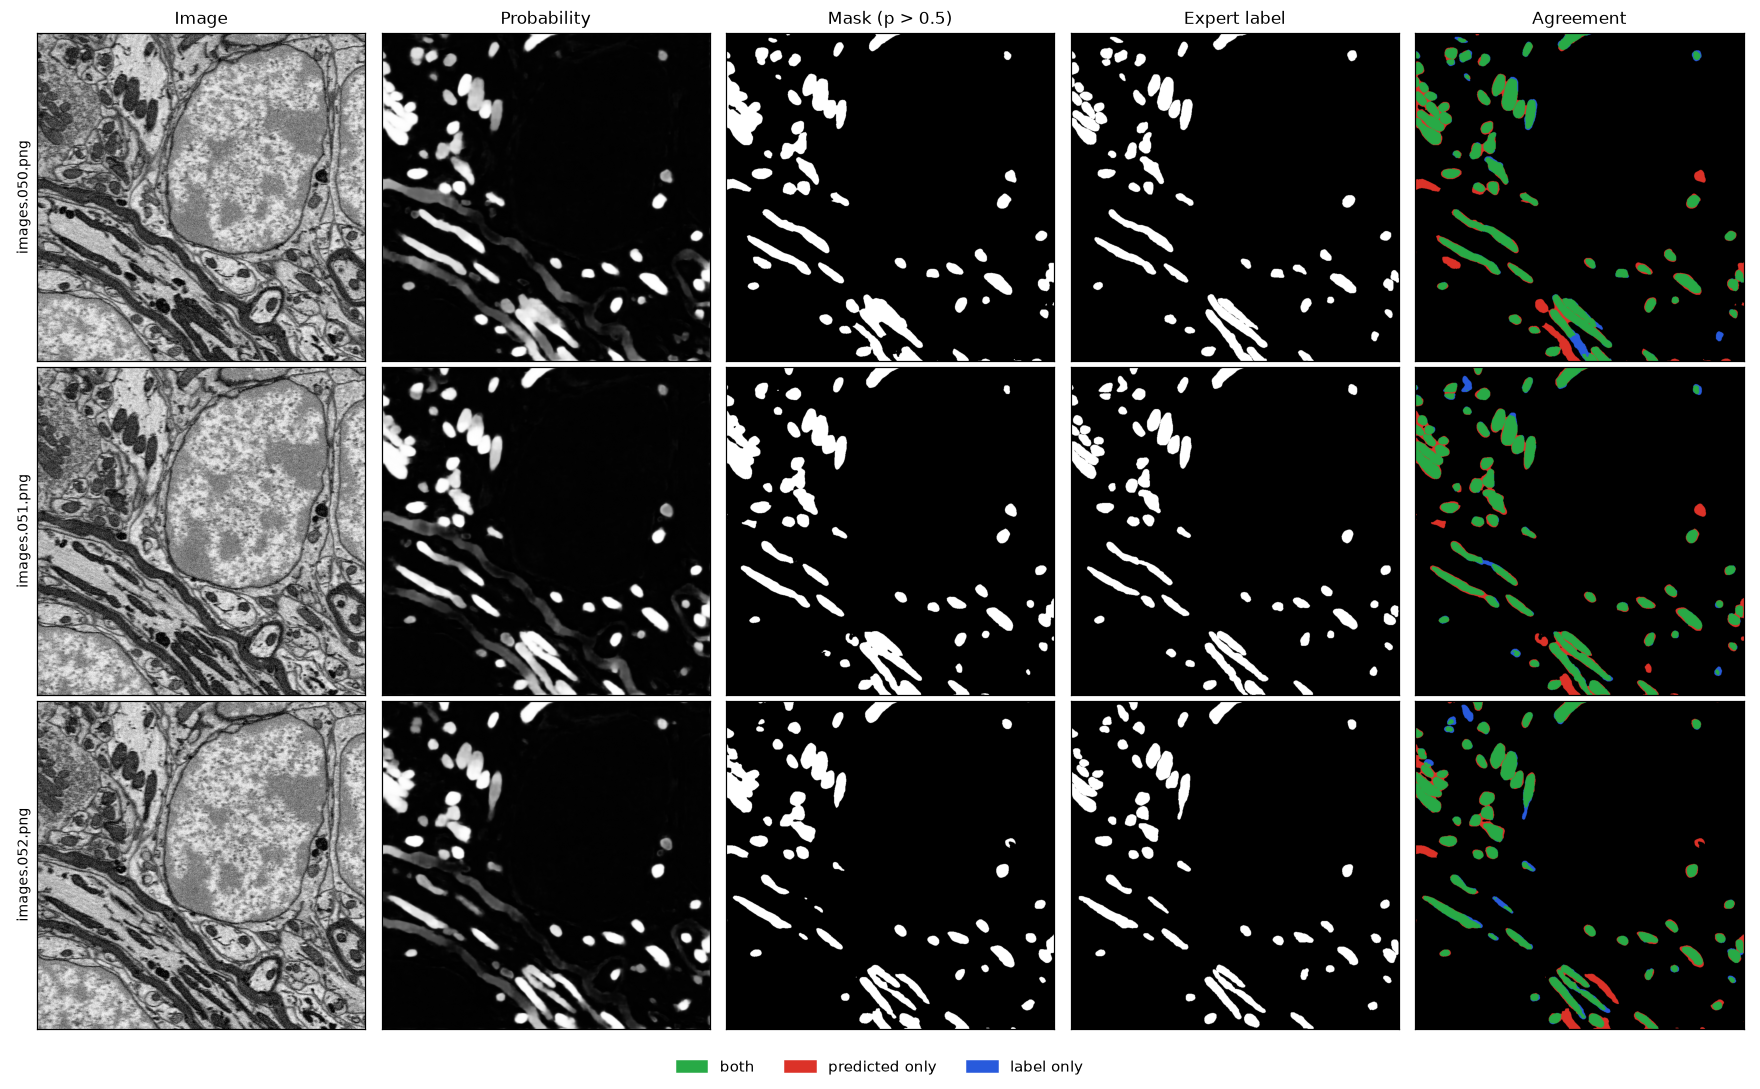

## What the numbers say

The pretrained model is already a strong fit for this data: Dice 0.84 and IoU 0.72 across all ten images, with very consistent per-image results (Dice 0.81–0.87, no outliers). The balance between the two error types is lopsided and worth noting — recall is 0.93 while precision is 0.77. In practice that means the model finds nearly all the mitochondria but slightly over-extends its boundaries, claiming some pixels the expert did not label. If you need tighter boundaries, raising the threshold above 0.5 would trade a little recall for precision; the scores are saved to `evaluation.csv` so you can compare thresholds or models directly.

The 6 seconds per image is the full-quality setting (all flipped and rotated copies averaged). If you later run this over a few hundred images, `augspeed=10` would cut that roughly tenfold at some cost in accuracy.

In [3]:
%%ask
Segment the mitochondria in the sample validation images with the pretrained mitochondria model.
Score the result against the expert labels, and show the first three images side by side with
their labels.

## 3. Plan a fine-tune

In [4]:
%%ask
I'd like to fine-tune the mitochondria model on the sample training slices: 300 updates, learning
rate 0.0005. Prepare the training data and show me the plan before starting anything.

The sample training slices are prepared and the plan is ready — nothing has started yet.

## Training data: mito_sample_training

| | |
|---|---|
| Labelled slices | 20 (1024 x 1024) |
| Augmented training files | 2.7 GB in `/tmp/cdeep3m/training_data/mito_sample_training` |
| Time | 10 s |

Training data name: `mito_sample_training` (temporary: kept only while the pod runs)

## Training plan: mito_finetune_300

**Settings used**

| Setting | Value |
|---|---|
| model | sbem-mitochondria |
| data | mito_sample_training |
| frames | 1fm |
| updates | 300 |
| learning_rate | 0.0005 |
| iter_size | 2 |
| batch | 5 |
| device | auto |
| threads | 2 |
| checkpoint_every | 100 |

Hardware: NVIDIA GeForce RTX 2080 Ti, 11264 MiB, 2 CPUs. Estimated time: about 2 min (0.4 s per update).

Nothing has started yet; training starts only when you confirm.

Two things worth knowing before you decide: the 2.7 GB of prepared training data sits in `/tmp/cdeep3m`, so it disappears if the pod stops — the finished model itself will be kept in the project folder. And at 300 updates this is a short fine-tune, so expect a modest shift from the pretrained model rather than a large one; the validation scores from the previous run (Dice 0.84) are the baseline to compare against.

Say the word and I'll start it with exactly these settings, then report the loss curve and re-score the validation images against the expert labels so you can see whether the fine-tune helped.

In [5]:
%%ask
That plan looks fine. Please start the training.

Training is running in the background with exactly the settings you approved.

## Training started: mito_finetune_300

**Settings used**

| Setting | Value |
|---|---|
| model | sbem-mitochondria |
| data | mito_sample_training |
| frames | 1fm |
| updates | 300 |
| learning_rate | 0.0005 |
| iter_size | 2 |
| batch | 5 |
| device | auto |
| threads | 2 |
| checkpoint_every | 100 |

Hardware: NVIDIA GeForce RTX 2080 Ti, 11264 MiB, 2 CPUs. Estimated time: about 2 min (0.4 s per update).
Model **sbem-mitochondria** ready for prediction (1fm).

Started in the background (process 1223). Run name: `mito_finetune_300`. It keeps running between questions; ask how the training is going at any time.

## Training status: mito_finetune_300 — running

| Network | Updates | Last loss | Average loss | Speed | Time left |
|---|---|---|---|---|---|
| 1fm | 0 of 300 | — | — | — | — |

The run is at its first update, so there is no loss reading yet — checkpoints are saved every 100 updates, and the whole run should finish in about 2 minutes. Ask me how it's going whenever you like and I'll pull the loss curve; once it's done I can turn it into a usable model and re-score the validation images against the expert labels so you can compare directly with the pretrained baseline of 0.84 Dice.

## 4. Follow the training (rerun this cell until it has finished)

The run has already finished — all 300 updates completed.

## Training status: mito_finetune_300 — finished

| Network | Updates | Last loss | Average loss | Speed | Time left |
|---|---|---|---|---|---|
| 1fm | 300 of 300 | 0.0665 | 0.0719 | 0.4 s/update | — |


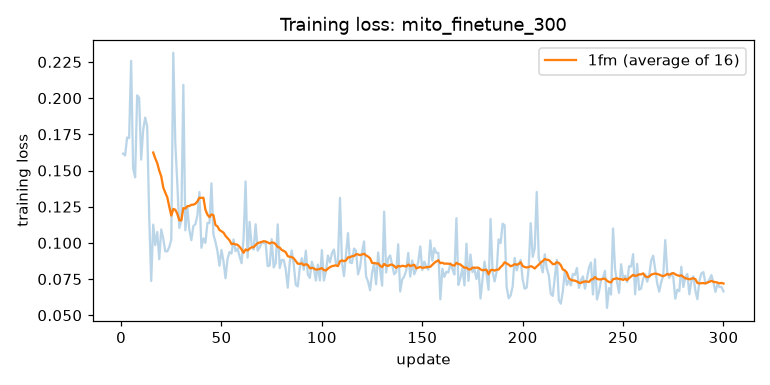

The loss fell to 0.0665 with an average of 0.0719 over the run, and it took about 2 minutes as estimated. The trained network is still only a run at this point — say the word and I'll turn it into a usable model and re-score the validation images against the expert labels so you can compare it directly with the pretrained baseline of 0.84 Dice.

In [6]:
%%ask
How is the training going?

## 5. Use the fine-tuned model

The fine-tuned model is built and scored — it came out slightly **worse** than the pretrained baseline.

## New model: mito_finetuned_300

| Network | Updates trained | Exported |
|---|---|---|
| 1fm | 300 | yes |

New model `mito_finetuned_300` (networks: 1fm) saved in `/home/jovyan/work/_User-Persistent-Storage_CephBlock_/Sage_demo/cdeep3m/models/mito_finetuned_300`; it can now segment images.

## Prediction: val_mito_finetuned

**Settings used**

| Setting | Value |
|---|---|
| model | mito_finetuned_300 |
| images | /opt/cdeep3m2/mito_testsample/validation/images |
| frames | 1fm |
| augspeed | 1 |
| device | auto |
| precision | auto |
| threshold | 0.5 |

**Result**

| | |
|---|---|
| Images segmented | 10 |
| Time | 56 s (5 s per image) |
| Ran on | vulkan |
| Probability maps (0–255) | `/home/jovyan/work/_User-Persistent-Storage_CephBlock_/Sage_demo/cdeep3m/predictions/val_mito_finetuned/probability` |
| Masks (probability > 0.5) | `/home/jovyan/work/_User-Persistent-Storage_CephBlock_/Sage_demo/cdeep3m/predictions/val_mito_finetuned/mask` |
| Overlays on the images | `/home/jovyan/work/_User-Persistent-Storage_CephBlock_/Sage_demo/cdeep3m/predictions/val_mito_finetuned/overlay` |

## Evaluation: val_mito_finetuned

Threshold 0.5 (a pixel is the object when its probability is above it); labels from `/opt/cdeep3m2/mito_testsample/validation/labels`, paired with the images in sorted order.

| Image | Label | Dice | IoU | Precision | Recall |
|---|---|---|---|---|---|
| images.050.png | mitos_3D.050.png | 0.7596 | 0.6124 | 0.8375 | 0.6949 |
| images.051.png | mitos_3D.051.png | 0.8243 | 0.7012 | 0.8624 | 0.7895 |
| images.052.png | mitos_3D.052.png | 0.8164 | 0.6897 | 0.8146 | 0.8182 |
| images.053.png | mitos_3D.053.png | 0.8235 | 0.7000 | 0.8257 | 0.8214 |
| images.054.png | mitos_3D.054.png | 0.8103 | 0.6811 | 0.8248 | 0.7963 |
| images.055.png | mitos_3D.055.png | 0.8231 | 0.6993 | 0.8315 | 0.8149 |
| images.056.png | mitos_3D.056.png | 0.8474 | 0.7351 | 0.8423 | 0.8525 |
| images.057.png | mitos_3D.057.png | 0.8243 | 0.7011 | 0.8120 | 0.8370 |
| images.058.png | mitos_3D.058.png | 0.8103 | 0.6811 | 0.8330 | 0.7888 |
| images.059.png | mitos_3D.059.png | 0.8070 | 0.6764 | 0.8140 | 0.8001 |
| **All 10 images** | | **0.8145** | **0.6870** | **0.8299** | **0.7996** |

Overall scores pool the pixels of all images; the mean of the per-image Dice is 0.8146.

## Comparison (reference: val_mito_pretrained)

Threshold 0.5; labels from `/opt/cdeep3m2/mito_testsample/validation/labels`; overall scores pool the pixels of all 10 images.

| Prediction | Model | Dice | IoU | Precision | Recall | Pixels predicted wrongly | Pixels missed |
|---|---|---|---|---|---|---|---|
| val_mito_pretrained | sbem-mitochondria | 0.8403 | 0.7246 | 0.7690 | 0.9262 | 220253 | 58445 |
| val_mito_finetuned | mito_finetuned_300 | 0.8145 | 0.6870 | 0.8299 | 0.7996 | 129778 | 158657 |
| change, val_mito_finetuned vs val_mito_pretrained | | -0.0258 | -0.0376 | +0.0609 | -0.1266 | -90475 | +100212 |

**Dice per image**

| Image | val_mito_pretrained | val_mito_finetuned | change, val_mito_finetuned |
|---|---|---|---|
| images.050.png | 0.8506 | 0.7596 | -0.0910 |
| images.051.png | 0.8684 | 0.8243 | -0.0441 |
| images.052.png | 0.8531 | 0.8164 | -0.0367 |
| images.053.png | 0.8458 | 0.8235 | -0.0223 |
| images.054.png | 0.8256 | 0.8103 | -0.0153 |
| images.055.png | 0.8254 | 0.8231 | -0.0023 |
| images.056.png | 0.8518 | 0.8474 | -0.0044 |
| images.057.png | 0.8354 | 0.8243 | -0.0110 |
| images.058.png | 0.8290 | 0.8103 | -0.0187 |
| images.059.png | 0.8110 | 0.8070 | -0.0041 |

val_mito_finetuned against val_mito_pretrained: Dice higher on 0 of 10 images, lower on 10, unchanged on 0.


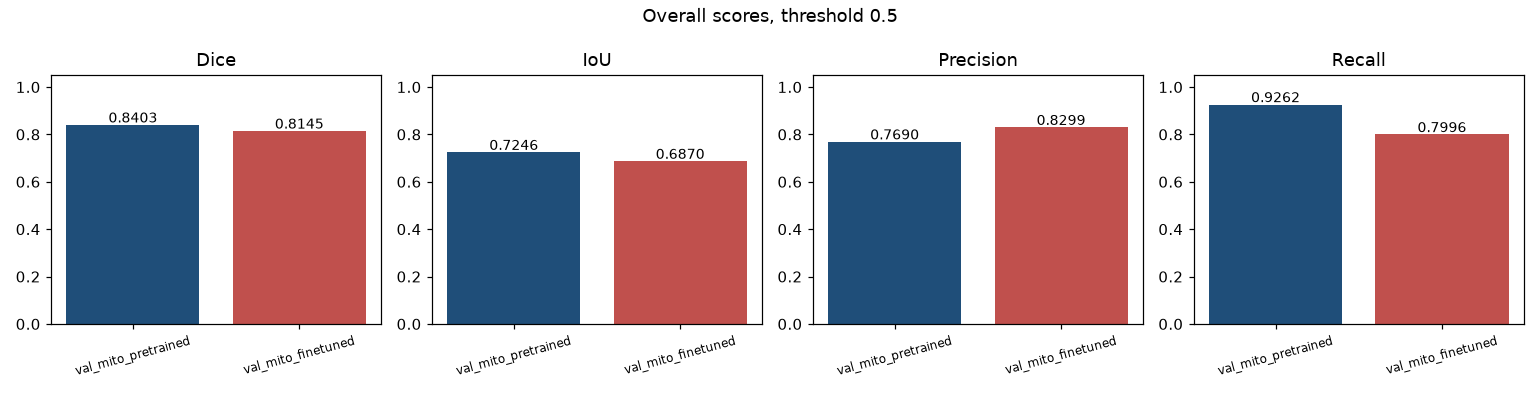

## What happened

The fine-tune did not help on this data: Dice fell from 0.8403 to 0.8145, and it lost on all ten images individually, so this is a consistent shift rather than noise. The interesting part is *how* it changed. Precision rose from 0.77 to 0.83 while recall collapsed from 0.93 to 0.80 — the model stopped over-reaching past the mitochondria boundaries (wrong pixels dropped by 90,475) but started missing real mitochondria instead (missed pixels rose by 100,212). It traded a small over-segmentation habit for a larger under-segmentation one, and the trade was net negative.

The likely cause is that 300 updates at learning rate 0.0005 is a very short, fairly aggressive nudge on only 20 training slices — enough to shift the model's operating point toward conservatism, not enough to teach it genuinely better boundaries. The pretrained model was already well matched to this data at 0.84 Dice, so there was little headroom to win and plenty to lose.

If you want to keep pursuing it, the sensible next attempts would be more updates (the default 3000 rather than 300) so the model has time to learn real structure instead of just shifting its threshold, and/or a lower learning rate. Alternatively, since the pretrained model's weakness is over-extension rather than detection, simply raising the prediction threshold above 0.5 would buy precision without any retraining at all — worth trying before spending more GPU time.

The fine-tuned model is saved in the project folder, so it survives a pod restart, and the pretrained model is untouched — you can go back to it at any time.

In [7]:
%%ask
Turn the finished training into a model, segment the sample validation images with it, and compare
its scores with the pretrained model's.